In [5]:
print("Student Performance Analysis")

# Student Performance Analysis

# ## Project Objective
# To analyse student academic performance
# using Python and Data Analytics.

# ## Tools Used
# 1. Python
# 2. Pandas
# 3. Matplotlib
# 4. Google Colab


Student Performance Analysis


## 1. Importing Libraries and Loading Dataset

In this section, we import the required Python libraries and load the student performance dataset using Pandas.

In [3]:
from google.colab import files
uploaded = files.upload()

Saving student+performance.zip to student+performance (1).zip


Extracted files:
student_performance_data/.student.zip_old
student_performance_data/student.zip


In [8]:
import zipfile

with zipfile.ZipFile('student_performance_data/student.zip', 'r') as zip_ref:
    zip_ref.extractall('student_data')

In [9]:
import os

os.listdir('student_data')

['student-mat.csv', 'student-merge.R', 'student-por.csv', 'student.txt']

In [10]:
import pandas as pd

df = pd.read_csv('student_data/student-mat.csv', sep=';')

## 2. Understanding the Dataset

In this section, we explore the dataset, identify its dimensions, examine column names and understand the information available.

In [11]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [12]:
df.shape

(395, 33)

In [13]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

## 3. Exploratory Data Analysis (EDA)

In this section, we analyse student academic performance using statistical methods.

We calculate:
- Average final grade
- Highest and lowest final grades
- Number of students passed and failed
- Pass percentage and failure percentage

In [14]:
df['G3'].mean()

np.float64(10.415189873417722)

In [15]:
df['G3'].max()

20

In [16]:
df['G3'].min()

0

In [19]:
(df['G3'] >= 10).sum()


np.int64(265)

In [20]:
(df['G3'] < 10).sum()

np.int64(130)

In [21]:
pass_count = (df['G3'] >= 10).sum()

total_students = len(df)

pass_percentage = (pass_count / total_students) * 100

print(pass_percentage)

67.08860759493672


In [36]:
fail_count = (df['G3'] < 10).sum()

total_students = len(df)

fail_percentage = (fail_count / total_students) * 100

print("Failure Percentage:", round(fail_percentage, 2), "%")

Failure Percentage: 32.91 %


## 4. Data Visualization

In this section, we use Matplotlib to represent student performance through graphs and charts.

Visualizations include:
- Pass vs Fail Bar Chart
- Student Pass vs Fail Pie Chart
- Study Time vs Average Grade
- Absences vs Average Grade

In [23]:
import matplotlib.pyplot as plt

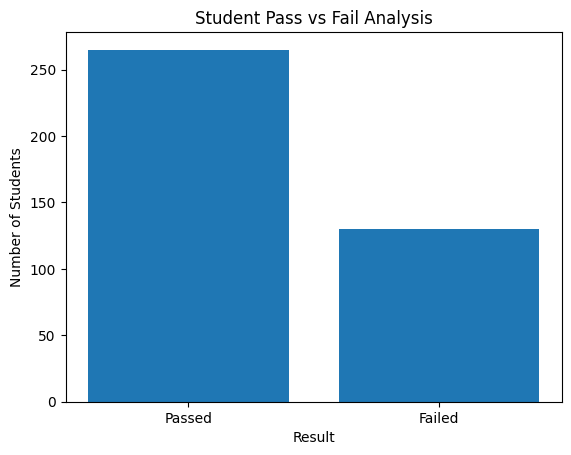

In [35]:
labels = ['Passed', 'Failed']

counts = [
    (df['G3'] >= 10).sum(),
    (df['G3'] < 10).sum()
]

plt.bar(labels, counts)

plt.title('Student Pass vs Fail Analysis')
plt.xlabel('Result')
plt.ylabel('Number of Students')

plt.show()

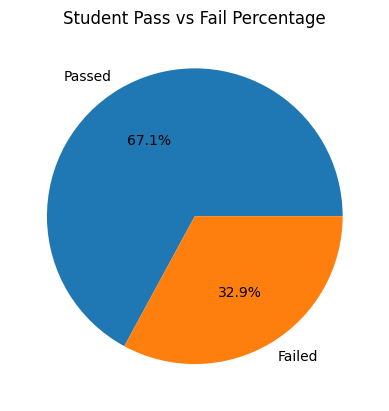

In [25]:
labels = ['Passed', 'Failed']
counts = [265, 130]

plt.pie(counts, labels=labels, autopct='%1.1f%%')

plt.title('Student Pass vs Fail Percentage')

plt.show()

In [26]:
df.groupby('studytime')['G3'].mean()

,G3
studytime,
1,10.047619
2,10.171717
3,11.400000
4,11.259259


## 5. Student Characteristics and Academic Performance

In this section, we investigate how different student characteristics relate to academic performance.

Analysis includes:
- Study time and final grades
- Gender and average final grades
- Student absences and final grades

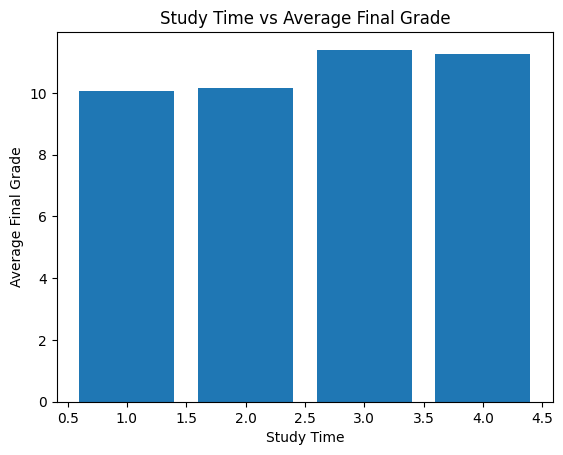

In [27]:
study_avg = df.groupby('studytime')['G3'].mean()

plt.bar(study_avg.index, study_avg.values)

plt.title('Study Time vs Average Final Grade')
plt.xlabel('Study Time')
plt.ylabel('Average Final Grade')

plt.show()

In [28]:
df.groupby('sex')['G3'].mean()

,G3
sex,
F,9.966346
M,10.914439


In [29]:
df.groupby('absences')['G3'].mean()

,G3
absences,
0,8.443478
1,13.000000
2,11.907692
3,11.500000
4,11.283019
5,11.600000
6,11.774194
7,11.857143
8,10.590909


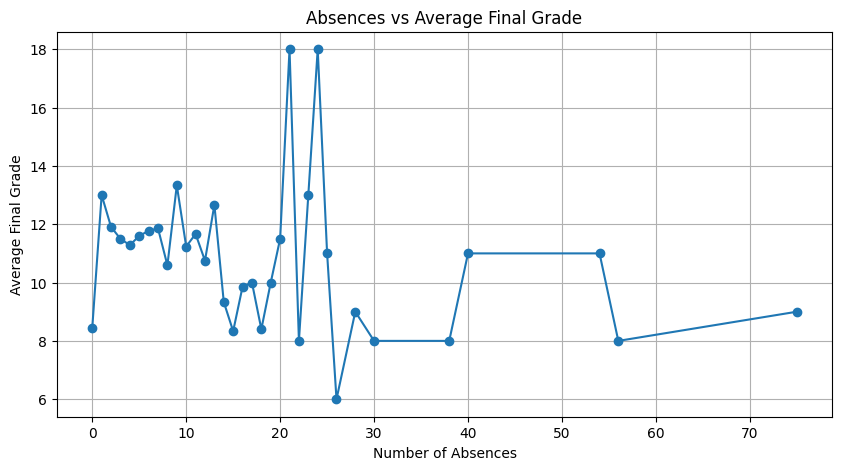

In [30]:
absence_avg = df.groupby('absences')['G3'].mean()

plt.figure(figsize=(10,5))

plt.plot(absence_avg.index, absence_avg.values, marker='o')

plt.title('Absences vs Average Final Grade')
plt.xlabel('Number of Absences')
plt.ylabel('Average Final Grade')

plt.grid()
plt.show()

## 6. Identifying Top and Bottom Performing Students

In this section, we identify the 10 students with the highest and lowest final grades using Pandas sorting techniques.

In [31]:
top_students = df.sort_values(by='G3', ascending=False)

top_students[['school', 'sex', 'age', 'studytime', 'absences', 'G3']].head(10)

,school,sex,age,studytime,absences,G3
47,GP,M,16,4,4,20
286,GP,F,18,3,5,19
374,MS,F,18,3,0,19
110,GP,M,15,1,6,19
8,GP,M,15,2,0,19
113,GP,M,15,1,10,19
91,GP,F,15,1,4,18
42,GP,M,15,2,2,18
36,GP,M,15,3,2,18
104,GP,M,15,2,0,18


In [32]:
bottom_students = df.sort_values(by='G3', ascending=True)

bottom_students[['school', 'sex', 'age', 'studytime', 'absences', 'G3']].head(10)

,school,sex,age,studytime,absences,G3
367,MS,F,17,1,0,0
389,MS,F,18,2,0,0
264,GP,F,18,3,0,0
259,GP,F,17,4,0,0
269,GP,F,18,2,0,0
244,GP,F,18,3,0,0
242,GP,M,16,1,0,0
239,GP,M,18,2,0,0
310,GP,F,19,2,0,0
296,GP,F,19,2,0,0


## 7. Key Findings

The analysis of the Student Performance Dataset revealed the following findings:

1. The dataset contains 395 students and 33 columns.
2. The average final grade (G3) is approximately 10.42.
3. The highest final grade is 20.
4. The lowest final grade is 0.
5. A total of 265 students passed.
6. A total of 130 students failed.
7. The pass percentage is approximately 67.09%.
8. The failure percentage is approximately 32.91%.

These findings provide an overview of student academic performance.

In [33]:
print("STUDENT PERFORMANCE ANALYSIS")
print("-----------------------------")

print("Total Students:", len(df))

print("Average Final Grade:", round(df['G3'].mean(), 2))

print("Highest Final Grade:", df['G3'].max())

print("Lowest Final Grade:", df['G3'].min())

print("Students Passed:", (df['G3'] >= 10).sum())

print("Students Failed:", (df['G3'] < 10).sum())

print("Pass Percentage:",
      round((df['G3'] >= 10).mean() * 100, 2), "%")

STUDENT PERFORMANCE ANALYSIS
-----------------------------
Total Students: 395
Average Final Grade: 10.42
Highest Final Grade: 20
Lowest Final Grade: 0
Students Passed: 265
Students Failed: 130
Pass Percentage: 67.09 %


## 8. Conclusion

This project analysed student academic performance using Python and Data Analytics.

Pandas was used for data loading, exploration and statistical analysis, while Matplotlib was used for data visualization.

The analysis helped identify student performance patterns based on final grades, study time, gender and absences.

This project provided practical experience in data cleaning, exploratory data analysis, data visualization and interpreting real-world datasets.

In [7]:
import os

os.listdir()

['.config',
 'student_performance_data',
 'student+performance.zip',
 'student+performance (1).zip',
 'sample_data']

# Student Performance Analysis Using Python

### Project 1 – Data Analytics Internship

**Objective**

The objective of this project is to analyse student academic performance using Python and identify patterns related to final grades, study time, absences and other student characteristics.

**Dataset:** Student Performance Dataset

**Tools and Technologies:**
- Python
- Google Colab
- Pandas
- Matplotlib
- Data Analysis and Visualization

**Dataset Size:** 395 students and 33 columns.

## 9. Data Cleaning and Quality Check

Data cleaning was performed to ensure the dataset was suitable for analysis.

The following checks were conducted:

1. Missing values were checked using `df.isnull().sum()`.
2. Duplicate records were checked using `df.duplicated().sum()`.

**Results:**
- No missing values were found.
- No duplicate records were found.

Therefore, the dataset was already clean and did not require additional cleaning.\

In [37]:
df.isnull().sum()

,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


In [38]:
df.duplicated().sum()

np.int64(0)

In [39]:
df.shape

(395, 33)

In [40]:
df.isnull().sum().sum()

np.int64(0)

In [41]:
df.duplicated().sum()

np.int64(0)